# Assignment 08: Species Distribution Modeling with elapid

## BIO597 Spatial Analysis of Biodiversity

Use `elapid` to prepare spatial data, fit a MaxEnt model, and ask how evaluation changes when we withhold whole geographic areas. You may reuse code from Lab08.

## Deliverable

Submit this completed notebook with maps, climate comparisons, ROC curves, an AUC summary table, and short written answers. Save your modeling points and AUC table. Use the lab's model defaults; no parameter search or suitability-raster export is required.


## 1. Import packages and load the occurrence records

Run this notebook from `docs/assignments`. The imports are provided so you can focus on the SDM workflow. If elapid is unavailable, use the same environment or installation instructions as the lab.

`np.random.seed(597)` makes the background draws repeatable when the notebook runs from top to bottom.


In [1]:
pip install elapid rasterio scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 125.8 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [elapid]2m2/4 [rasterio]
Note: you may need to restart the kernel to use updated packages.


In [5]:
import elapid as ela
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio import plot as rioplot
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.metrics import RocCurveDisplay

np.random.seed(597)
amphibians = gpd.read_file("../data/amphibians.geojson")
amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 2. Choose a species

Choose a common Maine amphibian other than the lab's pickerel frog (*Lithobates palustris*). Start with at least 200 records. Filter the occurrence table to your species and store the result as `species_points`.


In [6]:
target_species = "Anaxyrus americanus"

# Select your species and store a copy as species_points.
species_points = amphibians[amphibians["species"] == target_species].copy()

display(species_points.head())

# Print the record count and coordinate reference system.
print("Number of records:", len(species_points))
print(species_points.crs)

,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,geometry
11,6520596403,Anaxyrus americanus,-70.456821,43.994143,9.0,2026.0,POINT (-70.45682 43.99414)
14,6520566821,Anaxyrus americanus,-70.684983,44.393545,5.0,2026.0,POINT (-70.68498 44.39354)
24,6520413611,Anaxyrus americanus,-69.822108,43.874055,10.0,2026.0,POINT (-69.82211 43.87406)
27,6520268523,Anaxyrus americanus,-69.017731,44.389835,2.0,2026.0,POINT (-69.01773 44.38984)
37,6520168034,Anaxyrus americanus,-68.857452,45.924545,9.0,2026.0,POINT (-68.85745 45.92454)


Number of records: 1689
EPSG:4326


**Why this species?** Give one biological reason for your choice.

Habitat generalists, bufotoxin is cool, and they are my favorite native amphibian since childhood. 

## 3. Set up the climate rasters

Use the same 19 Maine bioclimatic rasters as the lab. The filenames and readable column names are provided below. Their order matters: each label must describe the corresponding raster.


In [7]:
bioclim_names = {
    'wc2.1_2.5m_bio_1.tif':  'Annual mean temperature',
    'wc2.1_2.5m_bio_2.tif':  'Mean diurnal temperature range',
    'wc2.1_2.5m_bio_3.tif':  'Isothermality',
    'wc2.1_2.5m_bio_4.tif':  'Temperature seasonality',
    'wc2.1_2.5m_bio_5.tif':  'Max temperature, warmest month',
    'wc2.1_2.5m_bio_6.tif':  'Min temperature, coldest month',
    'wc2.1_2.5m_bio_7.tif':  'Annual temperature range',
    'wc2.1_2.5m_bio_8.tif':  'Mean temperature, wettest quarter',
    'wc2.1_2.5m_bio_9.tif':  'Mean temperature, driest quarter',
    'wc2.1_2.5m_bio_10.tif': 'Mean temperature, warmest quarter',
    'wc2.1_2.5m_bio_11.tif': 'Mean temperature, coldest quarter',
    'wc2.1_2.5m_bio_12.tif': 'Annual precipitation',
    'wc2.1_2.5m_bio_13.tif': 'Precipitation, wettest month',
    'wc2.1_2.5m_bio_14.tif': 'Precipitation, driest month',
    'wc2.1_2.5m_bio_15.tif': 'Precipitation seasonality',
    'wc2.1_2.5m_bio_16.tif': 'Precipitation, wettest quarter',
    'wc2.1_2.5m_bio_17.tif': 'Precipitation, driest quarter',
    'wc2.1_2.5m_bio_18.tif': 'Precipitation, warmest quarter',
    'wc2.1_2.5m_bio_19.tif': 'Precipitation, coldest quarter',
}

rasters = [f"../data/bioclim_ME/{var}" for var in bioclim_names]
labels = list(bioclim_names.values())


## 4. Map the records over temperature

Open `rasters[0]` (annual mean temperature), plot it with `rioplot.show()`, and overlay your species' points. Reproject the points to the raster CRS when plotting, as in the lab. Keep this first raster path as `mean_temp_raster` for sampling.


/srv/conda/envs/notebook/lib/python3.13/site-packages/matplotlib/colors.py:816: RuntimeWarning: overflow encountered in multiply
  xa *= self.N


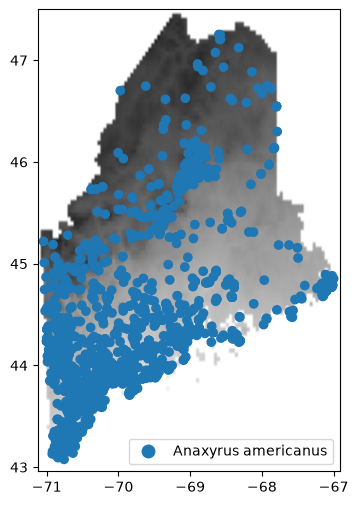

In [8]:
mean_temp_raster = rasters[0]

# Plot annual mean temperature and overlay species_points.
# Add a title naming your species.
fig, ax = plt.subplots(figsize=(6,6))
with rio.open(mean_temp_raster, 'r') as src:
    rioplot.show(src, ax=ax, cmap="gray")
    species_points.to_crs(src.crs).plot(column='species', ax=ax, legend=True)

**Interpretation:** Are records spread across Maine or concentrated in particular places? Why might a gap in records fail to indicate a true absence?

Records occur across the state but are concentrated along the coast, in southern Maine, and along the central Mountains. A gap in records does not indicate a true absence as occurrence records are subject to bias including ease of access dependent on proximity to other features (e.g., roads), areas of interest, public land, etc. 

## 5. Compare two background samples

Draw 1,000 points with `ela.sample_raster()` and another 1,000 with `ela.sample_bias_file()`, using annual mean temperature as the bias file. Drop duplicate geometries in each sample, following the lab, and report the remaining counts. Map the two samples side by side.

The biased sample favors cells with larger temperature values. This is a demonstration of sampling bias; temperature alone does not establish where observers actually searched.


count                                     917
unique                                    917
top       POINT (-67.1875 45.104166666666664)
freq                                        1
dtype: object
count                                    908
unique                                   908
top       POINT (-69.22916666666667 46.3125)
freq                                       1
dtype: object


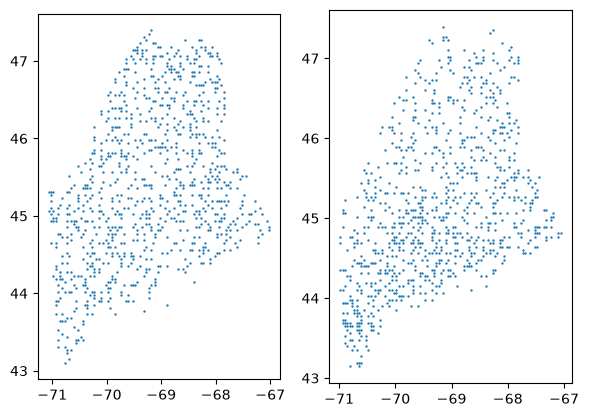

In [9]:
count = 1000

# Create pseudoabsence with ela.sample_raster().
pseudoabsence = ela.sample_raster(mean_temp_raster, count)

# Create pseudoabsence_bias with ela.sample_bias_file().
pseudoabsence_bias = ela.sample_bias_file(mean_temp_raster, count)

# Drop duplicate points, print the remaining counts, and map both samples.
pseudoabsence.drop_duplicates(inplace=True)
print(pseudoabsence.describe())
pseudoabsence_bias.drop_duplicates(inplace=True)
print(pseudoabsence_bias.describe())

# pseudoabsence.plot(markersize=0.5)
# pseudoabsence_bias.plot(markersize=0.5)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(6,6))

pseudoabsence.plot(markersize=0.5, ax = ax1)
pseudoabsence_bias.plot(markersize=0.5, ax = ax2)
plt.tight_layout()

**Interpretation:** How do the two geographic samples differ? Explain why background choice can change the species–climate relationship learned by a model.

The biased sample favors cells with higher temperature values, so point density is higher in southern Maine where higher temperatures occur. Background choice affects the species-climate relationship learned by the model because the model compares climate at presence sites to climate at background sites. By biasing the background sites appropriately, there is less weight given to sites where the species is unlikely to occur. 

Choose one sample for the remaining analysis and keep it fixed. The line below uses the uniform sample; change it to `pseudoabsence_bias` if you choose the biased sample.

**Background choice and justification:**


In [10]:
background_points = pseudoabsence_bias

# I selected the biased sample to reflect relatively diffuse sampling in northern Maine. 


## 6. Extract climate values with `ela.annotate()`

Annotate `species_points.geometry` and your chosen `background_points` using `rasters`, `labels`, `drop_na=True`, and `quiet=True`. Store the results as `presence` and `background`. Report the number of usable rows in each table.

Annotation means extracting raster values at point locations. `drop_na=True` removes points falling on raster NoData cells.


In [11]:
# Annotate presence and background points, following Lab08.
presence = ela.annotate(
    species_points.geometry,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)

# we'll use the biased sample locations
background = ela.annotate(
    background_points,
    rasters,
    labels=labels,
    drop_na=True,
    quiet=True,
)
# Print the usable counts and display presence.head().
print("Number of usable presence counts:", len(presence))
print("Number of usable background counts:", len(background))
display(presence.head())

Number of usable presence counts: 1581
Number of usable background counts: 908


,Annual mean temperature,Mean diurnal temperature range,Isothermality,Temperature seasonality,"Max temperature, warmest month","Min temperature, coldest month",Annual temperature range,"Mean temperature, wettest quarter","Mean temperature, driest quarter","Mean temperature, warmest quarter","Mean temperature, coldest quarter",Annual precipitation,"Precipitation, wettest month","Precipitation, driest month",Precipitation seasonality,"Precipitation, wettest quarter","Precipitation, driest quarter","Precipitation, warmest quarter","Precipitation, coldest quarter",geometry
0,6.875500,11.462334,28.995077,987.470398,26.136000,-13.396000,39.531998,2.555333,17.938667,18.782667,-5.710000,1162.0,120.0,84.0,11.347319,332.0,258.0,266.0,285.0,POINT (-70.45682 43.99414)
1,5.877167,12.145000,29.549879,1023.904968,25.955999,-15.144000,41.099998,1.270000,-6.012000,18.200666,-7.208000,1101.0,115.0,70.0,13.020443,312.0,228.0,289.0,242.0,POINT (-70.68498 44.39354)
2,7.694676,9.431944,26.710979,915.900757,25.222223,-10.088889,35.311111,3.715741,18.269444,18.833334,-3.831481,1154.0,121.0,77.0,14.027859,337.0,245.0,250.0,296.0,POINT (-69.82211 43.87406)
3,7.017667,10.758667,28.504311,955.339661,25.803999,-11.940000,37.743999,2.839333,18.583332,18.583332,-5.118000,1205.0,136.0,82.0,16.672430,366.0,255.0,255.0,295.0,POINT (-69.01773 44.38984)
4,2.863000,11.243333,27.074102,1079.739014,23.208000,-18.320000,41.528000,15.930000,-9.733334,15.930000,-10.804000,1124.0,113.0,64.0,15.799123,334.0,222.0,334.0,239.0,POINT (-68.85745 45.92454)


## 7. Compare recorded and available environments

Use the plotting recipe below to compare annual mean temperature, annual precipitation, and precipitation seasonality. These are the same three variables considered in Lab07. Density-scaled histograms let us compare shapes despite different sample sizes.


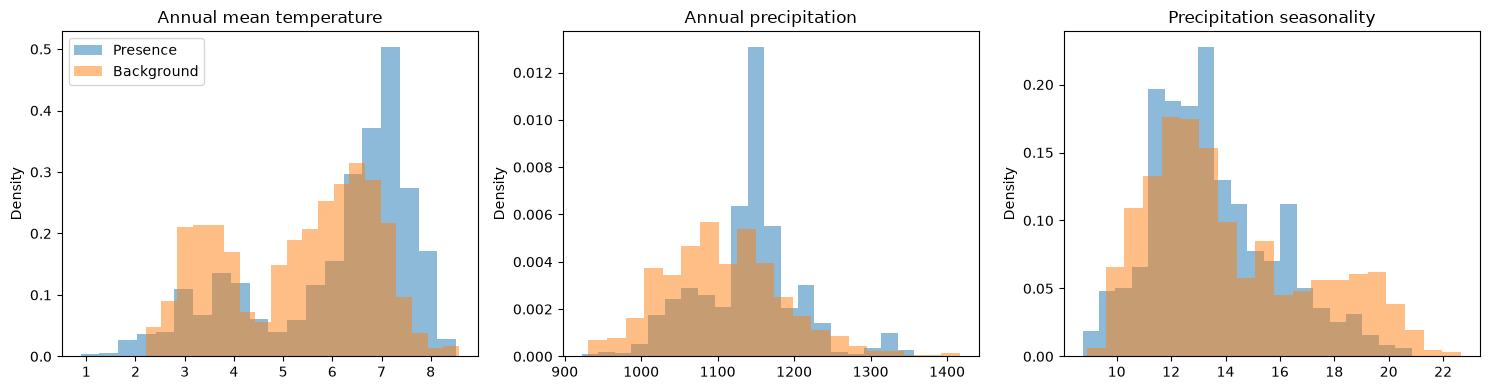

In [12]:
comparison_labels = [labels[0], labels[11], labels[14]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, ax in zip(comparison_labels, axes):
    ax.hist(presence[label], bins=20, density=True, alpha=0.5, label="Presence")
    ax.hist(background[label], bins=20, density=True, alpha=0.5, label="Background")
    ax.set_title(label)
    ax.set_ylabel("Density")

axes[0].legend()
plt.tight_layout()
plt.show()


**Interpretation:** Choose one variable. Does your species' recorded environment differ from the sampled background? Describe the pattern without assuming it proves a habitat preference.

The species recorded environment is similar to the sampled background. Both background and presence reflect a bimodal distribution. The background data have relatively symmetric peak heights and presence data have asymmetric peak heights. 

## 8. Calculate geographic sample weights

Following the lab, use `ela.distance_weights(..., n_neighbors=-1)` to calculate a `SampleWeight` column separately for presence and background. Pass points projected to `EPSG:26919`, which uses meters. Plot presence points colored by their weights.

The weights give relatively isolated observations more influence than observations in dense clusters. They do not turn an unobserved location into a confirmed absence.


<Axes: >

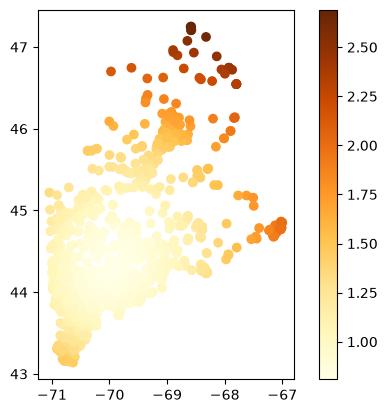

In [13]:
# Calculate presence["SampleWeight"] using presence.to_crs("EPSG:26919").
# Calculate background["SampleWeight"] the same way.
# Plot the presence weights with a legend.

presence['SampleWeight'] = ela.distance_weights(presence.to_crs('EPSG:26919'), n_neighbors=-1)
background['SampleWeight'] = ela.distance_weights(background.to_crs('EPSG:26919'), n_neighbors=-1)
presence.plot(column='SampleWeight', legend=True, cmap='YlOrBr')

**Interpretation:** Where are the largest weights? Why would decimal degrees be a poor unit for the distance calculations?

The largest weights are found in the northern-most and eastern-most observed occurrences. A projected coordinate system like UTM is more appropriate for distance calculations because it uses standardized grid sizes (meters) and represents a flat map surface rather than angle-based, unequal degrees as used by geographic coordinate systems that represent map surfaces as spherical.

## 9. Stack the tables and define predictors

Use `ela.stack_geodataframes(presence, background, add_class_label=True)` and project the result to `EPSG:26919`. Call the result `merged` and display the counts in its `class` column.

`class` is 1 for presence and 0 for background. Select only the named climate columns as predictors. `SampleWeight`, class labels, geometry, and later split labels must stay out of the predictor table.


In [14]:
# Stack presence and background as merged, then project it to EPSG:26919.
# Display the counts of each class.
merged = ela.stack_geodataframes(
    presence,
    background,
    add_class_label=True,
).to_crs('EPSG:26919')

print(merged['class'].value_counts())

X = merged[labels]
y = merged["class"]
sample_weight = merged["SampleWeight"]


class
1    1581
0     908
Name: count, dtype: int64


## 10. Fit MaxEnt and calculate a training AUC

Create `maxent = ela.MaxentModel()` and fit it with `X`, `y`, and `sample_weight=sample_weight`. Predict scores for `X`.

This first check uses the same rows for learning and evaluation, as in the lab's “naive” model. It is a **training score**, not a test of new locations.

**ROC AUC** measures how well scores rank presence above background. A value near 0.5 indicates little ranking ability; a higher value indicates better separation of these labels. The ROC curve shows the tradeoff as we change the cutoff for calling a score high: more recorded presences exceed the cutoff, but more background points may exceed it too. AUC does not establish true occupancy probability.


Unweighted naive AUC score: 0.852
Weighted naive AUC score  : 0.846


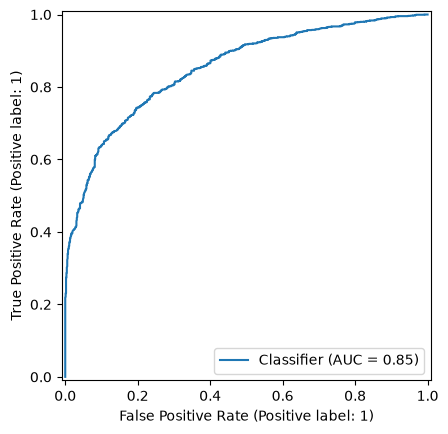

In [15]:
# Fit maxent with X, y, and sample_weight.
maxent = ela.MaxentModel()
maxent.set_params(n_cpus=4)


# Predict X and store the scores as naive_prediction.
maxent.fit(X, y, sample_weight=sample_weight)
naive_prediction = maxent.predict(X)


# Calculate naive_auc with metrics.roc_auc_score(y, naive_prediction).
# Also calculate naive_weighted_auc using sample_weight=sample_weight.
# Print both scores and plot a ROC curve with RocCurveDisplay.from_predictions().
print(f"Unweighted naive AUC score: {metrics.roc_auc_score(y, naive_prediction):0.3f}")
RocCurveDisplay.from_predictions(y, naive_prediction)
print(f"Weighted naive AUC score  : {metrics.roc_auc_score(y, naive_prediction, sample_weight=sample_weight):0.3f}")


**Interpretation:** Why might evaluating the same rows used to fit a model give an overly encouraging impression of performance?

If the model has already seen the data, it is "predicting" rules that it already knows.

## 11. Make a geographic train/test split

Use `ela.checkerboard_split(merged, grid_size=50_000)` to divide points into alternating 50 km squares. This distance is in meters because `merged` is projected.

Check the class counts in both groups: each needs presence and background rows to calculate AUC. The provided plotting recipe adds a split label for display only.


Training labels:
class
1    846
0    465
Name: count, dtype: int64
Test labels:
class
1    733
0    443
Name: count, dtype: int64


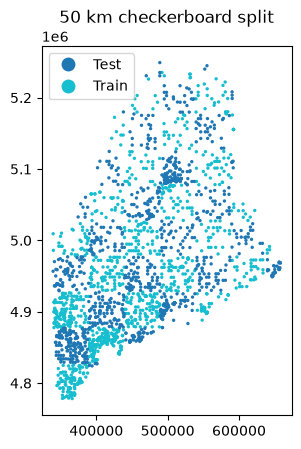

In [16]:
grid_size = 50_000
train, test = ela.checkerboard_split(merged, grid_size=grid_size)
print("Training labels:")
print(train["class"].value_counts())
print("Test labels:")
print(test["class"].value_counts())

train["split"] = "Train"
test["split"] = "Test"
checker = ela.stack_geodataframes(train, test)
checker.plot(column="split", markersize=2, legend=True)
plt.title("50 km checkerboard split")
plt.show()


## 12. Refit using training points and evaluate test points

Build training and test predictor tables using only `labels`, as below. Refit `maxent` on the training rows and their weights, then predict the test rows. Calculate unweighted and weighted test AUCs, storing them as `checker_auc` and `checker_weighted_auc`. Plot the test ROC curve.

In weighted AUC, test weights affect the contribution of each test row. They do not mean the model learned from the test labels.


In [ ]:
Xtrain = train[labels]
ytrain = train["class"]
weight_train = train["SampleWeight"]
Xtest = test[labels]
ytest = test["class"]
weight_test = test["SampleWeight"]

# Fit maxent using only Xtrain, ytrain, and weight_train.
# Predict Xtest and calculate checker_auc and checker_weighted_auc.
# Print the scores and plot the test ROC curve.


## Apply the trained model to the ME clipped rasters

In [ ]:
output_raster = "______________.tif"
# Use ela.apply_model_to_rasters() to apply the fitted model to the raster stack
# and write the result to the output_raster file

# use rio.open() to read the predicted tif back into memory
# and plot it with imshow()

**Interpretation:** Did test AUC differ from training AUC? Describe what each score evaluates. A lower test score does not automatically prove that spatial autocorrelation caused the difference: the training size and environments also changed. A higher test score does not automatically establish a reliable map.

## 13. Give the other squares a turn

For a simple two-fold spatial cross-validation, reverse the roles: create a new MaxEnt model, train it using `Xtest`, `ytest`, and `weight_test`, then evaluate its predictions for `Xtrain`. Store the unweighted and weighted scores as `reverse_auc` and `reverse_weighted_auc`.

No new background draw or checkerboard split is needed.


In [ ]:
# Create reverse_model with the same settings.
# Fit on Xtest with ytest and weight_test; predict Xtrain.
# Calculate reverse_auc and reverse_weighted_auc against ytrain.
# Print the scores.


**Interpretation:** Were the two directions equally easy to predict? Suggest one geographic or biological reason for a difference. Swapping the regions gives each group a turn as test data; it does not remove every source of observation bias.

## 14. Inspect one buffered leave-one-out split

The lab also demonstrates buffered leave-one-out validation. For each test presence, it removes nearby training points so the model must predict farther from its training data.

Run the code below to inspect **one split**, using a 50 km buffer. No repeated model fitting is required here. `next()` takes just the first split that the splitter produces. This visualization is not a complete validation or an AUC estimate.


In [ ]:
subset = merged.sample(n=min(200, len(merged)), random_state=597).reset_index(drop=True)
distance = 50_000
bloo = ela.BufferedLeaveOneOut(distance=distance)
train_idx, test_idx = next(bloo.split(subset, class_label="class"))
buffer_train = subset.iloc[train_idx]
buffer_test = subset.iloc[test_idx]

fig, ax = plt.subplots(figsize=(6, 6))
subset.plot(ax=ax, color="lightgray", markersize=5, label="All sampled points")
buffer_train.plot(ax=ax, color="teal", markersize=5, label="Retained training points")
buffer_test.buffer(distance).boundary.plot(ax=ax, color="coral")
buffer_test.plot(ax=ax, color="red", markersize=40, label="Test presence")
ax.legend()
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.tick_params(axis="x", labelrotation=45)
ax.set_title("One held-out presence and its 50 km exclusion buffer")
plt.show()


**Interpretation:** What happened to points inside the buffer? How does this test a different prediction question from randomly withholding records? Explain why a single held-out presence cannot by itself give a ROC AUC.

## 15. Summarize and save your results

Make a three-row table with evaluation names, unweighted AUCs, and weighted AUCs:

* Training rows scored by the all-data model.
* First checkerboard direction: train on `train`, evaluate `test`.
* Reversed direction: train on `test`, evaluate `train`.

Save it as `Assignment08_auc_scores.csv`, without a DataFrame index. Save `merged` as `Assignment08_modeling_points.gpkg` using `driver="GPKG"`, preserving its geometry, climate columns, labels, weights, and projected CRS.


In [ ]:
# Build an AUC summary table from the six scores you stored.
# Display it and save it to Assignment08_auc_scores.csv.
# Save merged to Assignment08_modeling_points.gpkg.


## Final reflection

Answer each question in two or three sentences, using your results.

1. Which preparation tasks did elapid simplify compared with earlier labs?
2. What do background sampling, geographic sample weights, and spatial train/test splitting each change?
3. Why do high AUC and a convincing ROC curve not establish a probability that your species occurs at a location?
4. What additional data or evaluation would most improve confidence in predictions for your species?

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, AUC table, saved points, and written answers. Commit and push the completed notebook and the two output files to your class GitHub repository.

```bash
git add docs/assignments/Assignment-08-SDM-Software.ipynb docs/assignments/Assignment08_auc_scores.csv docs/assignments/Assignment08_modeling_points.gpkg
git commit -m "Complete elapid SDM assignment"
git push
```

## References

* [elapid geospatial tools](https://earth-chris.github.io/elapid/module/geo/)
* [elapid MaxEnt model](https://earth-chris.github.io/elapid/sdm/maxent/)
* [elapid spatial train/test splitting](https://earth-chris.github.io/elapid/module/train_test_split/)
